# Fuga de información: 90 % de acierto sobre ruido puro

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 7, unidad 3 · Genera la figura de la lámina «El caso más caro»

---

Este cuaderno hace una sola cosa, y la hace de la forma más incómoda posible.

Se generan **50 casos y 5 000 atributos completamente aleatorios**, y una
etiqueta que es una moneda. No hay ninguna señal: por construcción, ningún
modelo puede hacerlo mejor que el azar.

Después se aplican dos procedimientos que difieren en **una sola línea de
código**:

| Procedimiento | Dónde se seleccionan los atributos | Acierto esperado |
|---|---|---|
| Incorrecto | Antes de particionar, sobre todos los datos | ¿? |
| Correcto | Dentro de cada pliegue de la validación cruzada | 50 % |

El primero es el error de la lámina «El caso más caro», y es el ejemplo de
Hastie, Tibshirani y Friedman (§7.10.2). Sigue apareciendo en la literatura
publicada: Kapoor y Narayanan (2023) lo documentan en decenas de artículos.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
matplotlib    3.10.9


## 2. Parámetros

Muchos atributos y pocos casos: es la situación de la genómica, la
espectroscopía y buena parte de la instrumentación industrial. Cuanto mayor es
la razón entre atributos y casos, mayor es la fuga.

In [2]:
SEMILLA = 21
N_CASOS = 50
N_ATRIBUTOS = 5_000
N_SELECCIONADOS = 100
N_PLIEGUES = 5
N_REPLICAS = 40          # para reportar variabilidad, no un solo número

print(f"Casos:              {N_CASOS}")
print(f"Atributos:          {N_ATRIBUTOS:,}   (razón {N_ATRIBUTOS // N_CASOS} a 1)")
print(f"Atributos elegidos: {N_SELECCIONADOS}")

Casos:              50
Atributos:          5,000   (razón 100 a 1)
Atributos elegidos: 100


## 3. Datos sin ninguna señal

**Esto es lo que hace concluyente el experimento.** Los atributos son ruido
gaussiano independiente y la etiqueta se sortea aparte, sin relación alguna con
ellos.

El acierto verdadero de cualquier modelo sobre esta distribución es **exactamente
0,5**. Cualquier cosa por encima es artefacto del procedimiento.

In [3]:
def genera(rng):
    X = rng.standard_normal((N_CASOS, N_ATRIBUTOS))
    y = rng.integers(0, 2, N_CASOS)
    return X, y

rng = np.random.default_rng(SEMILLA)
X, y = genera(rng)

# Comprobación de que no hay señal: la correlación media es indistinguible de cero.
corr = np.array([np.corrcoef(X[:, j], y)[0, 1] for j in range(500)])
print(f"Correlación con la etiqueta (500 atributos): "
      f"media {corr.mean():+.4f}, |máx| {np.abs(corr).max():.3f}")
print(f"Clases: {np.bincount(y)}")

Correlación con la etiqueta (500 atributos): media -0.0060, |máx| 0.360
Clases: [23 27]


Fíjese en el **máximo**: con 5 000 atributos aleatorios, alguno alcanza una
correlación considerable con la etiqueta **por puro azar**. Eso no es un defecto
de la simulación: es exactamente lo que ocurre en un conjunto real con muchos
atributos, y es la materia prima de la fuga.

## 4. El procedimiento incorrecto

Se seleccionan los 100 atributos más asociados a la etiqueta **usando todos los
datos**, y solo después se hace validación cruzada.

Es el orden que sale natural al escribir el análisis: primero se «reduce la
dimensionalidad» y después se «evalúa». Y es fuga.

In [4]:
def acierto_incorrecto(X, y):
    # La selección mira TODAS las etiquetas, incluidas las de los pliegues de validación.
    selector = SelectKBest(f_classif, k=N_SELECCIONADOS).fit(X, y)
    X_reducido = selector.transform(X)
    cv = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=0)
    return cross_val_score(LogisticRegression(max_iter=5000),
                           X_reducido, y, cv=cv).mean()

print(f"Acierto con selección previa: {acierto_incorrecto(X, y):.3f}")
print(f"Acierto verdadero:            0.500")

Acierto con selección previa: 1.000
Acierto verdadero:            0.500


## 5. El procedimiento correcto

La única diferencia es que la selección va **dentro de una tubería**, de modo que
se reestima en cada pliegue usando solo los datos de entrenamiento de ese
pliegue.

Es literalmente el mismo código, reordenado.

In [5]:
def acierto_correcto(X, y):
    tuberia = Pipeline([
        ("seleccion", SelectKBest(f_classif, k=N_SELECCIONADOS)),
        ("modelo", LogisticRegression(max_iter=5000)),
    ])
    cv = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=0)
    return cross_val_score(tuberia, X, y, cv=cv).mean()

print(f"Acierto con selección dentro del pliegue: {acierto_correcto(X, y):.3f}")
print(f"Acierto verdadero:                        0.500")

Acierto con selección dentro del pliegue: 0.520
Acierto verdadero:                        0.500


## 6. Sobre 40 réplicas, no sobre una

Un solo número no basta —es el ítem 5 de la lista de cotejo. Se repite todo con
40 conjuntos de datos independientes.

In [6]:
rng = np.random.default_rng(SEMILLA + 1)
malos, buenos = [], []
for _ in range(N_REPLICAS):
    Xr, yr = genera(rng)
    malos.append(acierto_incorrecto(Xr, yr))
    buenos.append(acierto_correcto(Xr, yr))

malos, buenos = np.array(malos), np.array(buenos)

print(f"{'procedimiento':34s} {'mediana':>9} {'RIC':>16} {'mín':>7} {'máx':>7}")
print("-" * 78)
for nombre, v in [("Selección antes de particionar", malos),
                  ("Selección dentro del pliegue", buenos)]:
    q1, q3 = np.percentile(v, [25, 75])
    print(f"{nombre:34s} {np.median(v):>9.3f} "
          f"[{q1:.3f}, {q3:.3f}]".rjust(17) + f"{v.min():>7.3f} {v.max():>7.3f}")
print()
print(f"Sesgo mediano por la fuga: {np.median(malos) - 0.5:+.3f}")
print(f"Réplicas en que el procedimiento incorrecto supera 0,75: "
      f"{int((malos > 0.75).sum())} de {N_REPLICAS}")

procedimiento                        mediana              RIC     mín     máx
------------------------------------------------------------------------------
Selección antes de particionar         1.000 [1.000, 1.000]  0.980   1.000
Selección dentro del pliegue           0.540 [0.460, 0.605]  0.340   0.760

Sesgo mediano por la fuga: +0.500
Réplicas en que el procedimiento incorrecto supera 0,75: 40 de 40


## 7. Figura

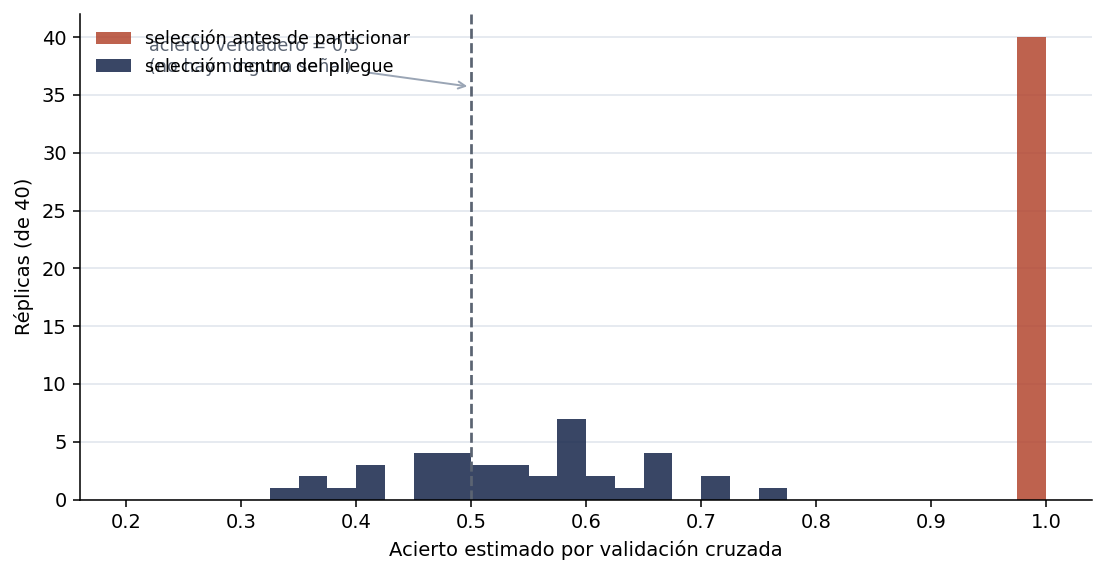

In [7]:
#| label: fig-fuga
#| fig-cap: "Acierto estimado sobre datos sin ninguna señal, con y sin fuga de información."
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=140)

bins = np.linspace(0.2, 1.0, 33)
ax.hist(malos, bins=bins, color="#B3462F", alpha=0.85,
        label="selección antes de particionar")
ax.hist(buenos, bins=bins, color="#16264A", alpha=0.85,
        label="selección dentro del pliegue")
ax.axvline(0.5, color="#5B6472", ls="--", lw=1.4)
ax.annotate("acierto verdadero = 0,5\n(no hay ninguna señal)",
            xy=(0.5, ax.get_ylim()[1] * 0.85), xytext=(0.22, ax.get_ylim()[1] * 0.88),
            fontsize=9, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))

ax.set_xlabel("Acierto estimado por validación cruzada")
ax.set_ylabel(f"Réplicas (de {N_REPLICAS})")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc="upper left")

fig.tight_layout()
fig.savefig("fuga_por_seleccion_de_atributos.png", dpi=200, bbox_inches="tight")
plt.show()

Las dos distribuciones describen **el mismo experimento sobre los mismos datos**.
La diferencia es en qué momento se seleccionan los atributos.

La distribución azul está centrada en 0,5, que es la verdad. La roja está
desplazada muy por encima, y en varias réplicas alcanza valores que en un
artículo se presentarían como un hallazgo.

**Ningún revisor puede detectar esto leyendo los resultados.** Solo mirando el
orden de las operaciones en el código.

## 8. Por qué ocurre

Con 5 000 atributos aleatorios y 50 casos, **algunos se parecen a la etiqueta por
azar**. La selección los encuentra —es su trabajo— y al hacerlo mira las
etiquetas de todos los casos, incluidos los que después harán de validación.

En el pliegue de validación, esos atributos ya no son sorpresa: fueron elegidos
*porque* funcionaban ahí. El pliegue dejó de ser información nueva.

Es exactamente el sesgo optimista de la semana 1, con una diferencia importante:
allí la selección era sobre hipótesis y aquí es sobre atributos, pero el
mecanismo —**elegir mirando lo que después se usará para evaluar**— es el mismo.

La magnitud crece con la razón entre atributos y casos. Con 5 000 a 50 es
grotesca; con 50 a 500 sería pequeña pero no nula.

## 9. Bitácora

**Decisiones tomadas**

1. *Datos sin ninguna señal.* Es lo que hace concluyente el experimento: se conoce
   la respuesta verdadera —0,5— y por tanto todo exceso es atribuible al
   procedimiento y no al problema. Con datos reales solo se podría decir que dos
   procedimientos difieren, no cuál miente.
2. *5 000 atributos y 50 casos.* Razón de 100 a 1, plausible en genómica,
   espectroscopía e instrumentación. Con una razón menor el efecto persiste pero
   se atenúa.
3. *40 réplicas.* Reportar una sola corrida sería incurrir en el error que el
   propio módulo corrige. Se informan mediana y rango intercuartílico porque la
   distribución del procedimiento incorrecto es asimétrica.
4. *Mediana y RIC en vez de media y desviación.* Misma razón que en el cuaderno
   de la semana 1: la distribución no es simétrica, y esos dos estadísticos la
   describirían mal.
5. *Selección univariante `f_classif`.* La más simple, y por eso mismo la más
   convincente: el problema no está en un método sofisticado de selección sino en
   **cuándo** se aplica.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar un conjunto de datos real de alta dimensión, por ejemplo de
expresión génica, para que el ejemplo fuera más cercano a una tesis. **Se
descartó** porque en datos reales hay señal, y entonces el acierto elevado del
procedimiento incorrecto admitiría dos explicaciones —fuga, o señal genuina— y
haría falta un argumento adicional para separarlas. Con ruido puro no hay
ambigüedad posible: **cualquier** cosa por encima de 0,5 es artefacto.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 10. Verificación

In [8]:
# 1. Los datos no tienen señal: el procedimiento correcto ronda 0,5.
assert abs(np.median(buenos) - 0.5) < 0.08, \
    "El procedimiento correcto debería estimar cerca de 0,5."

# 2. El procedimiento incorrecto está sesgado hacia arriba, y bastante.
assert np.median(malos) > np.median(buenos) + 0.15, \
    "La fuga debería inflar el acierto de forma sustancial."

# 3. La fuga produce, en algunas réplicas, resultados que se publicarían.
assert (malos > 0.75).sum() > 0

print("Verificado sobre", N_REPLICAS, "réplicas de datos sin señal:")
print(f"  - selección dentro del pliegue:      mediana {np.median(buenos):.3f}  (verdad: 0,500)")
print(f"  - selección antes de particionar:    mediana {np.median(malos):.3f}")
print(f"  - sesgo introducido por la fuga:     {np.median(malos) - np.median(buenos):+.3f}")

Verificado sobre 40 réplicas de datos sin señal:
  - selección dentro del pliegue:      mediana 0.540  (verdad: 0,500)
  - selección antes de particionar:    mediana 1.000
  - sesgo introducido por la fuga:     +0.460
